# MolFormer embeddings

- This notebook generates embeddings across several datasets using the **MolFormer** molecular embedding model
- The three datasets are the MCES dataset by Kretschmer et al (2025), a 30K subset of the ZINC database, and the Biogen ADMET dataset.
- You will need to edit the file paths in the relevant section below.

# Imports

In [6]:
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import torch
from transformers import AutoModel, AutoTokenizer
import rdkit
from rdkit import Chem
from sklearn.metrics.pairwise import cosine_similarity

## File paths

In [ ]:
BIOGEN_PATH  = ''
MCES_PATH    = ''
ZINC30K_PATH = ''

# Model set-up

In [2]:
MODEL_ID = "ibm-research/MoLFormer-XL-both-10pct"
REVISION = "compat-v4"

model = AutoModel.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    deterministic_eval=True,
    trust_remote_code=True,
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    trust_remote_code=True,
)

model.eval()

MolformerModel(
  (embeddings): MolformerEmbeddings(
    (word_embeddings): Embedding(2362, 768, padding_idx=2)
    (dropout): Dropout(p=0.2, inplace=False)
  )
  (encoder): MolformerEncoder(
    (layer): ModuleList(
      (0-11): 12 x MolformerLayer(
        (attention): MolformerAttention(
          (self): MolformerSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (rotary_embeddings): MolformerRotaryEmbedding()
            (feature_map): MolformerFeatureMap(
              (kernel): ReLU()
            )
          )
          (output): MolformerSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )


In [3]:
total = sum(p.numel() for p in model.parameters())
print(f"{total:,} parameters")
print(f"{total / 1e6:.1f}M parameters")

44,375,040 parameters
44.4M parameters


In [4]:
def embed(smiles):
    batch_size = 256
    all_embeddings = []

    with torch.inference_mode():
        for i in tqdm(range(0, len(smiles), batch_size)):
            batch = smiles[i:i + batch_size]

            inputs = tokenizer(
                batch,
                padding=True,
                truncation=True,
                max_length=202,
                return_tensors="pt"
            )

            outputs = model(**inputs)

            emb = outputs.pooler_output.cpu().numpy()
            all_embeddings.append(emb)

    embeddings = np.vstack(all_embeddings)
    return embeddings

# MCES

In [ ]:
distances = np.load(MCES_PATH)

In [9]:
mces   = distances['mces']
smiles = distances['smiles']

print(mces.shape)
print(smiles.shape)

(2012094766,)
(63437,)


In [ ]:
embeddings = embed(list(smiles))
np.save('MolFormer MCES embeddings.npy', embeddings)

100%|██████████| 248/248 [1:09:59<00:00, 16.94s/it]


In [ ]:
embeddings = np.load('MCES/MolFormer MCES embeddings.npy')

X = np.asarray(embeddings, dtype=np.float32)
n = X.shape[0]

# Normalize rows
norms = np.linalg.norm(X, axis=1, keepdims=True)
X = X / np.clip(norms, 1e-12, None)

m = n * (n - 1) // 2

pairwise_cosine = np.memmap(
    "MolFormer MCES pairwise cosines.dat",
    dtype="float32",
    mode="w+",
    shape=(m,),
)

offset = 0
chunk_size = 1000

for i_start in tqdm(range(0, n, chunk_size)):
    i_end = min(i_start + chunk_size, n)

    for i in range(i_start, i_end):
        sims = X[i] @ X[i + 1:].T
        pairwise_cosine[offset:offset + len(sims)] = sims
        offset += len(sims)

pairwise_cosine.flush()

print("Expected length:", m)
print("Written length:", offset)

100%|██████████| 64/64 [03:05<00:00,  2.90s/it]


Expected length: 2012094766
Written length: 2012094766


In [ ]:
n = 63437
m = n * (n - 1) // 2

pair_indices = np.memmap(
    "MolFormer pairwise indices.dat",
    dtype=np.uint32,
    mode="w+",
    shape=(m, 2),
)

offset = 0

for i in tqdm(range(n - 1)):
    n_pairs = n - i - 1

    pair_indices[offset:offset + n_pairs, 0] = i
    pair_indices[offset:offset + n_pairs, 1] = np.arange(
        i + 1,
        n,
        dtype=np.uint32,
    )

    offset += n_pairs

pair_indices.flush()

print("Expected:", m)
print("Written:", offset)

100%|██████████| 63436/63436 [00:34<00:00, 1840.56it/s]

Expected: 2012094766
Written: 2012094766


# MCES figure example

100%|██████████| 1/1 [00:08<00:00,  8.72s/it]


Cosine similarity: [[0.9530775]]


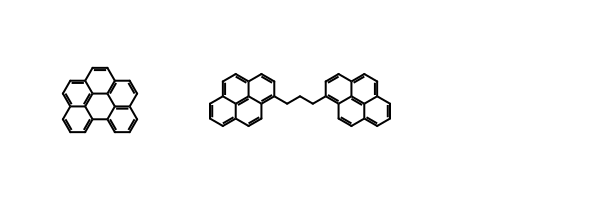

In [7]:
close_pair_a = "C1=CC2=C3C(=C1)C4=CC=CC5=C4C6=C(C=C5)C=CC(=C36)C=C2"
close_pair_b = "C1=CC2=C3C(=C1)C=CC4=C(C=CC(=C43)C=C2)CCCC5=C6C=CC7=CC=CC8=C7C6=C(C=C8)C=C5"

close_pair_mol_a = Chem.MolFromSmiles(close_pair_a)
close_pair_mol_b = Chem.MolFromSmiles(close_pair_b)

embeddings = embed([close_pair_a, close_pair_b])
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([close_pair_mol_a, close_pair_mol_b])

100%|██████████| 1/1 [00:03<00:00,  3.79s/it]

Cosine similarity: [[0.37903202]]


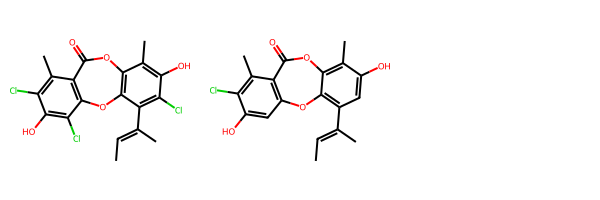

In [8]:
distant_pair_a = "CC=C(C)C1=C(C(=C(C2=C1OC3=C(C(=C(C(=C3C(=O)O2)C)Cl)O)Cl)C)O)Cl"
distant_pair_b = "CC=C(C)C1=CC(=C(C2=C1OC3=C(C(=C(C(=C3)O)Cl)C)C(=O)O2)C)O"

distant_pair_mol_a = Chem.MolFromSmiles(distant_pair_a)
distant_pair_mol_b = Chem.MolFromSmiles(distant_pair_b)

embeddings = embed([distant_pair_a, distant_pair_b])
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([distant_pair_mol_a, distant_pair_mol_b])

# Biogen

In [ ]:
biogen = pd.read_csv(BIOGEN_PATH)
smiles = biogen['SMILES'].tolist()

In [ ]:
embeddings = embed(list(smiles))
np.save('MolFormer Biogen embeddings.npy', embeddings)

100%|██████████| 14/14 [02:53<00:00, 12.40s/it]


# ZINC

In [ ]:
data = pd.read_csv(ZINC30K_PATH)[:30000]
smiles = data['SMILES'].tolist()

In [ ]:
embeddings = embed(list(smiles))
np.save('MolFormer ZINC30K embeddings.npy', embeddings)

100%|██████████| 118/118 [16:21<00:00,  8.32s/it]
